In [1]:
print("setup works")

setup works


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

In [13]:
df = pd.read_csv("c:/Users/Kareena/OneDrive/Documents/fraud-project/data/bs140513_032310.csv")
df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


In [14]:
print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])
df.info()

Rows   : 594643
Columns: 10
<class 'pandas.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  str    
 2   age          594643 non-null  str    
 3   gender       594643 non-null  str    
 4   zipcodeOri   594643 non-null  str    
 5   merchant     594643 non-null  str    
 6   zipMerchant  594643 non-null  str    
 7   category     594643 non-null  str    
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), str(7)
memory usage: 45.4 MB


In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
step,"594,643.00",94.99,51.05,0.00,52.00,97.00,139.00,179.00
amount,"594,643.00",37.89,111.40,0.00,13.74,26.90,42.54,"8,329.96"
fraud,"594,643.00",0.01,0.11,0.00,0.00,0.00,0.00,1.00


In [16]:
print("Missing cells:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing cells: 0
Duplicate rows: 0


fraud
0    587443
1      7200
Name: count, dtype: int64
fraud
0   98.79
1    1.21
Name: proportion, dtype: float64


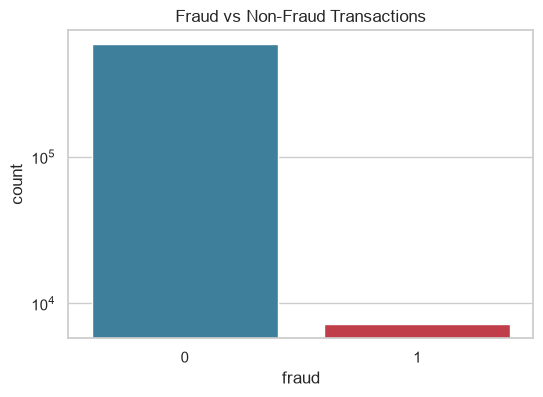

In [17]:
TARGET = "fraud"
print(df[TARGET].value_counts())
print((df[TARGET].value_counts(normalize=True) * 100).round(3))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x=TARGET, data=df, hue=TARGET, palette=["#2e86ab", "#d62839"], legend=False)
ax.set_title("Fraud vs Non-Fraud Transactions")
ax.set_yscale("log")
plt.show()

In [18]:
pd.DataFrame({
    "dtype": df.dtypes,
    "unique_values": df.nunique(),
    "example": df.iloc[0]
})

,dtype,unique_values,example
step,int64,180,0
customer,str,4112,'C1093826151'
age,str,8,'4'
gender,str,4,'M'
zipcodeOri,str,1,'28007'
merchant,str,50,'M348934600'
zipMerchant,str,1,'28007'
category,str,15,'es_transportation'
amount,float64,23767,4.55
fraud,int64,2,0


In [19]:
print("Step range:", df["step"].min(), "to", df["step"].max())

Step range: 0 to 179


In [20]:
print(df.groupby(TARGET)["amount"].agg(["count", "mean", "median", "max", "sum"]).round(2))

        count   mean  median      max           sum
fraud                                              
0      587443  31.85   26.61 2,144.86 18,708,432.56
1        7200 530.93  319.18 8,329.96  3,822,671.17


In [22]:
df = pd.read_csv("C:\\Users\\Kareena\\OneDrive\\Documents\\fraud-project\\data\\bs140513_032310.csv")

text_cols = ["customer", "age", "gender", "merchant", "category"]
for col in text_cols:
    df[col] = df[col].str.replace("'", "", regex=False)

df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,C1093826151,4,M,'28007',M348934600,'28007',es_transportation,4.55,0
1,0,C352968107,2,M,'28007',M348934600,'28007',es_transportation,39.68,0
2,0,C2054744914,4,F,'28007',M1823072687,'28007',es_transportation,26.89,0
3,0,C1760612790,3,M,'28007',M348934600,'28007',es_transportation,17.25,0
4,0,C757503768,5,M,'28007',M348934600,'28007',es_transportation,35.72,0


In [23]:

df = df.drop(columns=["zipcodeOri", "zipMerchant"])
df.columns.tolist()

['step',
 'customer',
 'age',
 'gender',
 'merchant',
 'category',
 'amount',
 'fraud']

In [24]:
# Age group codes (as documented for BankSim)
age_map = {
    "0": "<=18", "1": "19-25", "2": "26-35", "3": "36-45",
    "4": "46-55", "5": "56-65", "6": ">65", "U": "Unknown"
}
df["age_group"] = df["age"].map(age_map)

# Gender codes. E is documented as Enterprise (a business account), U as Unknown.
# Please confirm this in the dataset description on Kaggle.
gender_map = {"M": "Male", "F": "Female", "E": "Enterprise", "U": "Unknown"}
df["gender"] = df["gender"].map(gender_map)

# Cleaner category names: es_travel -> Travel
df["category"] = (df["category"].str.replace("es_", "", regex=False)
                  .str.replace("and", " & ", regex=False)
                  .str.title())

df[["age", "age_group", "gender", "category"]].head()

,age,age_group,gender,category
0,4,46-55,Male,Transportation
1,2,26-35,Male,Transportation
2,4,46-55,Female,Transportation
3,3,36-45,Male,Transportation
4,5,56-65,Male,Transportation


In [25]:
# step is a day number (0-179), not a real date, so we group in blocks
df["day"] = df["step"]
df["week"] = df["step"] // 7 + 1
df["month"] = df["step"] // 30 + 1     # 30-day blocks, labelled Month 1 to 6
df["fraud_label"] = df["fraud"].map({0: "Normal", 1: "Fraud"})

df[["step", "day", "week", "month"]].drop_duplicates().head()

,step,day,week,month
0,0,0,1,1
2430,1,1,1,1
4854,2,2,1,1
7316,3,3,1,1
9815,4,4,1,1


In [26]:
print("Zero-amount rows:", (df["amount"] == 0).sum())
print("Missing values  :", df.isnull().sum().sum())
print("\nUnmapped labels (should all be 0):")
print(df[["age_group", "gender"]].isnull().sum())
print("\nCategories:\n", df["category"].value_counts())

Zero-amount rows: 52
Missing values  : 0

Unmapped labels (should all be 0):
age_group    0
gender       0
dtype: int64

Categories:
 category
Transportation        505119
Food                   26254
Health                 16133
Wellness & Beauty      15086
Fashion                 6454
Bars & Restaurants      6373
Hyper                   6098
Sports & Toys           4002
Tech                    2370
Home                    1986
Hotelservices           1744
Otherservices            912
Contents                 885
Travel                   728
Leisure                  499
Name: count, dtype: int64


In [9]:
import pandas as pd

raw = pd.read_csv("../data/bs140513_032310.csv")

print(raw.shape)
print(raw.columns.tolist())

raw.head(3)

(594643, 13)
['step', 'customer', 'age', 'gender', 'merchant', 'category', 'amount', 'fraud', 'age_group', 'day', 'week', 'month', 'fraud_label']


,step,customer,age,gender,merchant,category,amount,fraud,age_group,day,week,month,fraud_label
0,0,C1093826151,4,Male,M348934600,Transportation,4.55,0,46-55,0,1,1,Normal
1,0,C352968107,2,Male,M348934600,Transportation,39.68,0,26-35,0,1,1,Normal
2,0,C2054744914,4,Female,M1823072687,Transportation,26.89,0,46-55,0,1,1,Normal


In [36]:
!git add .

In [37]:
!git commit -m "Step 3-4: business questions and data cleaning"

[main 3ef0346] Step 3-4: business questions and data cleaning
 3 files changed, 1190309 insertions(+)
 create mode 100644 01_data_understanding.ipynb
 create mode 100644 data/bs140513_032310.csv
 create mode 100644 data/bsNET140513_032310.csv


In [38]:
!git push

To https://github.com/afroz-project/financial-fraud-detection.git
   3cf4c3f..3ef0346  main -> main


In [7]:
import os

file_path = r"C:/Users/Kareena/OneDrive/Documents/fraud-project/data/banksim_clean.csv"

print("File exists:", os.path.exists(file_path))
print("File size:", os.path.getsize(file_path), "bytes")

File exists: True
File size: 0 bytes


In [8]:
with open(file_path, "r", encoding="utf-8") as f:
    print(repr(f.read(500)))

''


In [10]:
import pandas as pd

df = pd.read_csv("../data/bs140513_032310.csv")

# 1. Remove quote marks
for col in ["customer", "age", "gender", "merchant", "category"]:
    df[col] = df[col].str.replace("'", "", regex=False)

# 2. Drop useless columns
df = df.drop(columns=["zipcodeOri", "zipMerchant"])

# 3. Readable labels
age_map = {"0": "<=18", "1": "19-25", "2": "26-35", "3": "36-45",
           "4": "46-55", "5": "56-65", "6": ">65", "U": "Unknown"}
df["age_group"] = df["age"].map(age_map)

gender_map = {"M": "Male", "F": "Female", "E": "Enterprise", "U": "Unknown"}
df["gender"] = df["gender"].map(gender_map)

df["category"] = (df["category"].str.replace("es_", "", regex=False)
                  .str.replace("and", " & ", regex=False)
                  .str.title())

# 4. Time columns
df["day"] = df["step"]
df["week"] = df["step"] // 7 + 1
df["month"] = df["step"] // 30 + 1
df["fraud_label"] = df["fraud"].map({0: "Normal", 1: "Fraud"})

# 5. Save
df.to_csv("../data/banksim_clean.csv", index=False)
print("Saved:", df.shape)

KeyError: "['zipcodeOri', 'zipMerchant'] not found in axis"

In [11]:
import pandas as pd

df = pd.read_csv("../data/bs140513_032310.csv")
print("Shape  :", df.shape)
print("Columns:", df.columns.tolist())
print(df["gender"].unique())
print(df["category"].unique()[:5])
df.head(3)

Shape  : (594643, 13)
Columns: ['step', 'customer', 'age', 'gender', 'merchant', 'category', 'amount', 'fraud', 'age_group', 'day', 'week', 'month', 'fraud_label']
<StringArray>
['Male', 'Female', 'Enterprise', 'Unknown']
Length: 4, dtype: str
<StringArray>
['Transportation', 'Health', 'Otherservices', 'Food', 'Hotelservices']
Length: 5, dtype: str


,step,customer,age,gender,merchant,category,amount,fraud,age_group,day,week,month,fraud_label
0,0,C1093826151,4,Male,M348934600,Transportation,4.55,0,46-55,0,1,1,Normal
1,0,C352968107,2,Male,M348934600,Transportation,39.68,0,26-35,0,1,1,Normal
2,0,C2054744914,4,Female,M1823072687,Transportation,26.89,0,46-55,0,1,1,Normal


In [12]:
import os

df.to_csv("../data/banksim_clean.csv", index=False)

check = pd.read_csv("../data/banksim_clean.csv")
print("File size (MB):", round(os.path.getsize("../data/banksim_clean.csv") / 1e6, 1))
print("Shape  :", check.shape)
print("Fraud %:", round(check["fraud"].mean() * 100, 2))

File size (MB): 46.7
Shape  : (594643, 13)
Fraud %: 1.21


In [13]:
!git add .

In [14]:
!git commit -m "Step 3-4: business questions and data cleaning"

[main 722252c] Step 3-4: business questions and data cleaning
 2 files changed, 1089 insertions(+)
 create mode 100644 notebooks/01_data_understanding.ipynb
 create mode 100644 notebooks/03_eda.ipynb


In [15]:
! git push

To https://github.com/afroz-project/financial-fraud-detection.git
   3ef0346..722252c  main -> main
